# 01 · LendingClub data: loading, target and first checks

This notebook turns the raw LendingClub file into the clean dataset used for modelling.

1. **Load** only columns known when the loan was approved, so no leakage (Methodology 1.2).
2. **Keep** loans issued 2007–2015 (Methodology 12.2).
3. **Remove** loans under the old credit policy and loans with no final outcome, and **define the target**: Fully Paid = 0, Charged Off / Default = 1 (Methodology 1.1).
4. **Check** the default rate by year and by grade, and how many loans were still running (Methodology 12).
5. **Save** the result to `data/processed/loans_2007_2015.parquet`.

**Output:** 826,606 loans, split into train (2007–2014) and test (2015). No model is built here.


## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# The notebook lives in notebooks/, so the project root is one level up
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

# The LendingClub file of accepted loans (.csv or .csv.gz)
RAW_FILE = sorted(p for p in RAW.rglob("*accepted*") if p.is_file() and p.name.endswith((".csv", ".csv.gz")))[0]
print(f"Raw file: {RAW_FILE.relative_to(ROOT)} ({RAW_FILE.stat().st_size / 1e6:,.0f} MB)")

# Train / test split by issue year (Methodology Section 12.1)
TRAIN_YEARS = range(2007, 2015)   # 2007–2014
TEST_YEARS = range(2015, 2016)    # 2015
TRAIN_COLOR, TEST_COLOR = "#4C72B0", "#DD8452"   # blue, orange

Raw file: data/raw/accepted_2007_to_2018Q4.csv.gz (393 MB)


## 1. Load application-time columns only

The model is used when someone applies for a loan, so it may only use information known on that day (Methodology Section 1.2). The raw file has 151 columns, many of them filled in after the loan was issued (for example `total_pymnt`, `recoveries`, `last_pymnt_d`, `out_prncp`). Rather than loading everything and removing those afterwards, the code uses an **allow-list**: only the columns listed below are ever read.

In [2]:
# Columns that define the target and the train/test split
ID_TARGET_DATE = ["id", "issue_d", "loan_status", "term"]

# Application-time features (known on the day the loan was approved)
FEATURES = [
    # the loan
    "loan_amnt", "int_rate", "installment", "grade", "sub_grade", "purpose",
    # the borrower
    "emp_length", "home_ownership", "annual_inc", "verification_status", "addr_state", "dti",
    # credit history at application
    "fico_range_low", "fico_range_high", "earliest_cr_line", "delinq_2yrs", "inq_last_6mths",
    "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc", "pub_rec_bankruptcies",
]

# Known post-issuance columns: listed only to check that none of them is ever loaded
LEAKAGE = ["total_pymnt", "recoveries", "last_pymnt_d", "out_prncp"]

ALLOWED = ID_TARGET_DATE + FEATURES
assert not set(ALLOWED) & set(LEAKAGE), "A leakage column is in the allow-list"

df = pd.read_csv(RAW_FILE, usecols=lambda c: c in ALLOWED, low_memory=False)

print(f"Loaded {len(df):,} rows and {df.shape[1]} columns")
print("Allowed columns missing from the file:", sorted(set(ALLOWED) - set(df.columns)) or "none")
print("Leakage columns loaded:", sorted(set(LEAKAGE) & set(df.columns)) or "none")

Loaded 2,260,701 rows and 28 columns
Allowed columns missing from the file: none
Leakage columns loaded: none


## 2. Keep loans issued 2007–2015

The file records each loan's status as of **December 2018**. A 36-month loan issued in December 2015 is due to finish in December 2018, so 2015 is the last year in which such loans have had time to reach a final outcome. Loans issued from 2016 onwards were often still running at the cut-off, and including them would bias the default rate (right-censoring, Methodology Section 12.2). LendingClub began lending in 2007.

`issue_d` is text such as `Dec-2015`. Rows where it cannot be read as a date are shown and then dropped.

In [12]:
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y", errors="coerce")

print(f"Dropped {df['issue_d'].isna().sum():,} rows with no valid issue date (LendingClub summary lines)")
df = df.dropna(subset=["issue_d"])
df["issue_year"] = df["issue_d"].dt.year
df["term"] = df["term"].str.strip()          # ' 36 months' -> '36 months'

df = df[df["issue_year"].between(2007, 2015)].copy()
print(f"Loans issued 2007–2015: {len(df):,}")

Dropped 0 rows with no valid issue date (LendingClub summary lines)
Loans issued 2007–2015: 884,691


## 3. Target and loans kept for modelling (Methodology Section 1.1)

Every loan status in 2007–2015:

In [4]:
df["loan_status"].value_counts().to_frame("loans").style.format("{:,}")

,loans
loan_status,
Fully Paid,"674,302"
Charged Off,"152,302"
Current,"55,224"
Does not meet the credit policy. Status:Fully Paid,"1,988"
Late (31-120 days),"1,696"
In Grace Period,813
Does not meet the credit policy. Status:Charged Off,761
Late (16-30 days),352
Default,2


Each loan has a status as of December 2018. We sort the statuses into three groups:

| Status | What it means | What we do |
|---|---|---|
| Fully Paid | the loan was repaid in full | keep, target = **0** (good) |
| Charged Off, Default | the borrower stopped paying and LendingClub wrote the loan off | keep, target = **1** (bad) |
| Current, In Grace Period, Late | the loan was still running in December 2018, so its outcome is unknown | **not used for modelling** |
| Does not meet the credit policy … | an early loan (2007–2010) given to a borrower LendingClub would later have refused | **removed** |

The model can only learn from loans whose outcome is known, so it uses only the first two groups. The loans still running are not thrown away straight away: section 4 of this notebook ("Loans and default rate by issue year") uses them to measure how many loans in each year had not finished by December 2018. This is the censoring problem described in Methodology Section 12.2.

This is why the code keeps two tables:

- **`df`**: all loans except the old-policy ones, *including* those still running. Used only in section 4 of this notebook.
- **`loans`**: only loans with a known outcome (target 0 or 1). This is the modelling dataset, and the one saved at the end.

In [5]:
# Remove loans issued outside LendingClub's standard credit policy
old_policy = df["loan_status"].str.startswith("Does not meet the credit policy")
print(f"Removed, old credit policy: {old_policy.sum():,}")
df = df[~old_policy].copy()

# Target: 0 = good, 1 = bad, missing = no final outcome yet
TARGET_MAP = {"Fully Paid": 0, "Charged Off": 1, "Default": 1}
df["target"] = df["loan_status"].map(TARGET_MAP)
df["resolved"] = df["target"].notna()

loans = df[df["resolved"]].copy()
loans["target"] = loans["target"].astype(int)

print(f"Standard-policy loans 2007–2015:   {len(df):,}")
print(f"  without a final outcome:         {(~df['resolved']).sum():,}")
print(f"  kept for modelling (`loans`):    {len(loans):,}")
print(f"Default rate among kept loans:     {loans['target'].mean():.1%}")

Removed, old credit policy: 2,749
Standard-policy loans 2007–2015:   884,691
  without a final outcome:         58,085
  kept for modelling (`loans`):    826,606
Default rate among kept loans:     18.4%


In [15]:
# =====================================================================
# 1. Data KEPT for modelling
# =====================================================================
print("1. KEPT FOR MODELLING  (table `loans`)")
print("   Loans with a known final outcome: Fully Paid (target 0) or Charged Off/Default (target 1).")
print(f"   {len(loans):,} loans x {loans.shape[1]} columns. First 10 shown:\n")
display(loans.head(10))

# =====================================================================
# 2. Loans NOT used for modelling, and why
# =====================================================================
unresolved = df[~df["resolved"]]

MEANING = {
    "Current":            "still running, all payments made on time",
    "In Grace Period":    "a payment is a few days late, within the allowed grace period",
    "Late (16-30 days)":  "still running, 2–4 weeks behind on payments",
    "Late (31-120 days)": "still running, 1–4 months behind on payments",
}

reasons = unresolved["loan_status"].value_counts().to_frame("loans")
reasons["share"] = reasons["loans"] / reasons["loans"].sum()
reasons["meaning in December 2018"] = reasons.index.map(MEANING)

print("\n2. NOT USED FOR MODELLING: loans still running in December 2018")
print("   Their outcome (repaid or defaulted) is unknown, so they cannot be given a target.")
print(f"   {len(unresolved):,} loans, by status:\n")
display(reasons.style.format({"loans": "{:,}", "share": "{:.1%}"}))

1. KEPT FOR MODELLING  (table `loans`)
   Loans with a known final outcome: Fully Paid (target 0) or Charged Off/Default (target 1).
   826,606 loans x 31 columns. First 10 shown:



,id,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,mort_acc,pub_rec_bankruptcies,issue_year,target,resolved
0,68407277,3600.0,36 months,13.99,123.03,C,C4,10+ years,MORTGAGE,55000.0,Not Verified,2015-12-01,Fully Paid,debt_consolidation,PA,5.91,0.0,Aug-2003,675.0,679.0,1.0,7.0,0.0,2765.0,29.7,13.0,1.0,0.0,2015,0,True
1,68355089,24700.0,36 months,11.99,820.28,C,C1,10+ years,MORTGAGE,65000.0,Not Verified,2015-12-01,Fully Paid,small_business,SD,16.06,1.0,Dec-1999,715.0,719.0,4.0,22.0,0.0,21470.0,19.2,38.0,4.0,0.0,2015,0,True
2,68341763,20000.0,60 months,10.78,432.66,B,B4,10+ years,MORTGAGE,63000.0,Not Verified,2015-12-01,Fully Paid,home_improvement,IL,10.78,0.0,Aug-2000,695.0,699.0,0.0,6.0,0.0,7869.0,56.2,18.0,5.0,0.0,2015,0,True
4,68476807,10400.0,60 months,22.45,289.91,F,F1,3 years,MORTGAGE,104433.0,Source Verified,2015-12-01,Fully Paid,major_purchase,PA,25.37,1.0,Jun-1998,695.0,699.0,3.0,12.0,0.0,21929.0,64.5,35.0,6.0,0.0,2015,0,True
5,68426831,11950.0,36 months,13.44,405.18,C,C3,4 years,RENT,34000.0,Source Verified,2015-12-01,Fully Paid,debt_consolidation,GA,10.20,0.0,Oct-1987,690.0,694.0,0.0,5.0,0.0,8822.0,68.4,6.0,0.0,0.0,2015,0,True
6,68476668,20000.0,36 months,9.17,637.58,B,B2,10+ years,MORTGAGE,180000.0,Not Verified,2015-12-01,Fully Paid,debt_consolidation,MN,14.67,0.0,Jun-1990,680.0,684.0,0.0,12.0,0.0,87329.0,84.5,27.0,4.0,0.0,2015,0,True
7,67275481,20000.0,36 months,8.49,631.26,B,B1,10+ years,MORTGAGE,85000.0,Not Verified,2015-12-01,Fully Paid,major_purchase,SC,17.61,1.0,Feb-1999,705.0,709.0,0.0,8.0,0.0,826.0,5.7,15.0,3.0,0.0,2015,0,True
8,68466926,10000.0,36 months,6.49,306.45,A,A2,6 years,RENT,85000.0,Not Verified,2015-12-01,Fully Paid,credit_card,PA,13.07,0.0,Apr-2002,685.0,689.0,1.0,14.0,1.0,10464.0,34.5,23.0,1.0,1.0,2015,0,True
9,68616873,8000.0,36 months,11.48,263.74,B,B5,10+ years,MORTGAGE,42000.0,Not Verified,2015-12-01,Fully Paid,credit_card,RI,34.80,0.0,Nov-1994,700.0,704.0,0.0,8.0,0.0,7034.0,39.1,18.0,1.0,0.0,2015,0,True
12,68338832,1400.0,36 months,12.88,47.10,C,C2,3 years,MORTGAGE,64000.0,Not Verified,2015-12-01,Fully Paid,other,NC,34.95,0.0,Jun-1996,700.0,704.0,0.0,17.0,0.0,37828.0,67.2,24.0,4.0,0.0,2015,0,True



2. NOT USED FOR MODELLING: loans still running in December 2018
   Their outcome (repaid or defaulted) is unknown, so they cannot be given a target.
   58,085 loans, by status:



,loans,share,meaning in December 2018
loan_status,,,
Current,"55,224",95.1%,"still running, all payments made on time"
Late (31-120 days),"1,696",2.9%,"still running, 1–4 months behind on payments"
In Grace Period,813,1.4%,"a payment is a few days late, within the allowed grace period"
Late (16-30 days),352,0.6%,"still running, 2–4 weeks behind on payments"


## 4. Loans and default rate by issue year

This is the key table for the validation design (Methodology Section 12). For each issue year:

- **issued**: standard-policy loans issued;
- **resolved**: loans with a final outcome by December 2018;
- **share_resolved**: resolved ÷ issued; a low value means many loans were still running (right-censoring, Section 12.2);
- **default_rate**: defaults ÷ resolved loans.

In [6]:
by_year = df.groupby("issue_year").agg(
    issued=("id", "size"),
    resolved=("resolved", "sum"),
    defaults=("target", "sum"),
)
by_year["share_resolved"] = by_year["resolved"] / by_year["issued"]
by_year["default_rate"] = by_year["defaults"] / by_year["resolved"]
by_year["sample"] = ["train" if y in TRAIN_YEARS else "test" for y in by_year.index]

by_year.style.format({"issued": "{:,}", "resolved": "{:,}", "defaults": "{:,.0f}",
                      "share_resolved": "{:.1%}", "default_rate": "{:.1%}"})

,issued,resolved,defaults,share_resolved,default_rate,sample
issue_year,,,,,,
2007,251,251,45,100.0%,17.9%,train
2008,"1,562","1,562",247,100.0%,15.8%,train
2009,"4,716","4,716",594,100.0%,12.6%,train
2010,"11,536","11,536","1,487",100.0%,12.9%,train
2011,"21,721","21,721","3,297",100.0%,15.2%,train
2012,"53,367","53,367","8,644",100.0%,16.2%,train
2013,"134,814","134,804","21,024",100.0%,15.6%,train
2014,"235,629","223,103","41,162",94.7%,18.4%,train
2015,"421,095","375,546","75,804",89.2%,20.2%,test


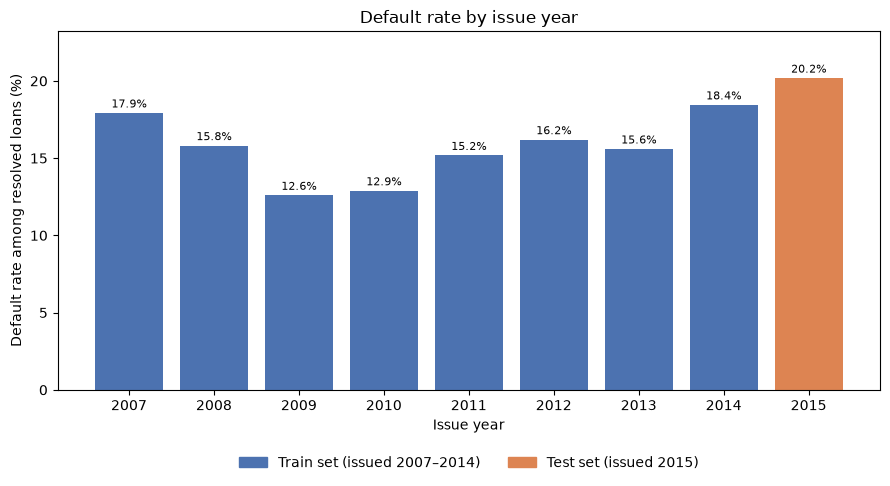

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = [TRAIN_COLOR if s == "train" else TEST_COLOR for s in by_year["sample"]]
bars = ax.bar(by_year.index.astype(str), by_year["default_rate"] * 100, color=colors)
ax.bar_label(bars, fmt="%.1f%%", fontsize=8, padding=2)

train_label = f"Train set (issued {TRAIN_YEARS[0]}–{TRAIN_YEARS[-1]})"
test_label = f"Test set (issued {TEST_YEARS[0]})" if len(TEST_YEARS) == 1 \
    else f"Test set (issued {TEST_YEARS[0]}–{TEST_YEARS[-1]})"

ax.legend(
    handles=[Patch(color=TRAIN_COLOR, label=train_label),
             Patch(color=TEST_COLOR, label=test_label)],
    loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False,
)
ax.set_title("Default rate by issue year")
ax.set_xlabel("Issue year")
ax.set_ylabel("Default rate among resolved loans (%)")
ax.set_ylim(0, by_year["default_rate"].max() * 100 * 1.15)
plt.tight_layout()
plt.show()

### By term

60-month loans take longer to finish, so censoring hits them harder. If the test years show a much lower share resolved and a higher default rate for 60-month loans than for 36-month loans, censoring explains part of the rise in default rate.

In [8]:
by_year_term = df.groupby(["issue_year", "term"]).agg(
    issued=("id", "size"),
    resolved=("resolved", "sum"),
    defaults=("target", "sum"),
)
by_year_term["share_resolved"] = by_year_term["resolved"] / by_year_term["issued"]
by_year_term["default_rate"] = by_year_term["defaults"] / by_year_term["resolved"]

table = by_year_term[["issued", "share_resolved", "default_rate"]].unstack("term")
formats = {col: "{:.1%}" if col[0] in ("share_resolved", "default_rate") else "{:,.0f}" for col in table.columns}
table.style.format(formats, na_rep="–")

## 5. Sanity check: default rate by grade

LendingClub assigned each loan a grade from A (safest) to G (riskiest). If the target is defined correctly, the default rate should rise steadily from A to G.

In [9]:
by_grade = loans.groupby("grade")["target"].agg(loans="size", default_rate="mean")
by_grade.style.format({"loans": "{:,}", "default_rate": "{:.1%}"})

,loans,default_rate
grade,,
A,"146,430",5.6%
B,"241,511",12.0%
C,"225,234",20.4%
D,"126,002",28.1%
E,"61,871",36.8%
F,"20,693",42.3%
G,"4,865",46.7%


## 6. Missing values in the features

Features with missing values need a decision before modelling. In the scorecard, missing values get their own bin (Methodology Section 3.4).

In [10]:
missing = loans[FEATURES].isna().mean().sort_values(ascending=False)
missing = missing[missing > 0].to_frame("share_missing")
missing.style.format("{:.2%}") if len(missing) else print("No missing values")

,share_missing
mort_acc,5.72%
emp_length,5.15%
pub_rec_bankruptcies,0.08%
revol_util,0.05%
dti,0.00%


## 7. Save the clean dataset

The saved file contains only loans with a final outcome, issued 2007–2015 under the standard credit policy, with the target and application-time features. It is written as Parquet (fast and compressed) to `data/processed/`, which is ignored by git, so the data never goes to GitHub.

In [11]:
clean = loans[ID_TARGET_DATE + ["issue_year", "target"] + FEATURES].reset_index(drop=True)

out = PROCESSED / "loans_2007_2015.parquet"
clean.to_parquet(out, index=False)

summary = pd.DataFrame({
    "loans": [len(clean),
              clean["issue_year"].isin(TRAIN_YEARS).sum(),
              clean["issue_year"].isin(TEST_YEARS).sum()],
    "default_rate": [clean["target"].mean(),
                     clean.loc[clean["issue_year"].isin(TRAIN_YEARS), "target"].mean(),
                     clean.loc[clean["issue_year"].isin(TEST_YEARS), "target"].mean()],
}, index=["all (2007–2015)",
          f"train ({TRAIN_YEARS[0]}–{TRAIN_YEARS[-1]})",
          f"test ({TEST_YEARS[0]})"])
summary["share"] = summary["loans"] / len(clean)

print(f"Saved {len(clean):,} loans x {clean.shape[1]} columns to {out.relative_to(ROOT)}")
summary.style.format({"loans": "{:,}", "default_rate": "{:.1%}"})

Saved 826,606 loans x 30 columns to data/processed/loans_2007_2015.parquet


,loans,default_rate,share
all (2007–2015),"826,606",18.4%,1.000000
train (2007–2014),"451,060",17.0%,0.545677
test (2015),"375,546",20.2%,0.454323
